# R-001 — Radar UAV Binary Classification (ResNet18)

## Completed experiment — verification and evaluation notebook

This notebook records the environment, dataset restoration, **completed** R-001 training-history verification, held-out evaluation, split-integrity checks, figures, and literature comparison. The actual training and evaluation implementations reside in the companion `src/` package and `configs/r001.json`, not in the notebook cells.

- **Task:** Binary radar-spectrogram classification (UAV vs non-UAV)
- **Model:** ImageNet-pretrained ResNet18
- **Source:** MathWorks–St Andrews dataset (original CSV splits)
- **Training:** 20/20 epochs completed; final model frozen
- **Evaluation:** 2,146 held-out samples; stored results are re-used without retraining
- **Artifacts:** Google Drive `RadarClassifier/Runs/R-001` and `RadarClassifier/Evaluations/R-001-final`

**Research boundary:** 100% accuracy on the supplied evaluation split does not demonstrate generalization to independent recording sessions. See Sections 13–18 for integrity and confounding checks.

**Safety:** Do not rerun initial training, modify the frozen configuration, or overwrite the published evaluation directory. This notebook deliberately skips evaluation if complete saved results are present. A new evaluator must supply the authorized dataset and trained checkpoint; the files are not bundled in GitHub.

## 1 — Verify GPU and numerical environment

The original training used Python 3.13.16, PyTorch 2.11.0+cu130 and a Tesla T4. This historical comparison is retained for reproducibility; **the 20-epoch training is finished and must not be resumed**.

In [1]:
import sys
import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("No CUDA GPU. Select a hosted T4 GPU runtime before continuing.")
print("GPU:", torch.cuda.get_device_name(0))
print("Prior environment: Python 3.13.16, PyTorch 2.11.0+cu130, Tesla T4")
print("If the numerical environment differs, STOP before attempting to resume.")

Python: 3.13.16
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Prior environment: Python 3.13.16, PyTorch 2.11.0+cu130, Tesla T4
If the numerical environment differs, STOP before attempting to resume.


## 2 — Mount Google Drive and verify saved archives/checkpoint

In [3]:
from google.colab import drive
from pathlib import Path
import json

drive.mount("/content/drive")

drive_root = Path("/content/drive/MyDrive/RadarClassifier")
archive_drive = drive_root / "Dataset/MathWorks-project-dataset.7z"
project_zip = drive_root / "Code/radar-classifier-r001.zip"
run_dir = drive_root / "Runs/R-001"
checkpoint = run_dir / "last.pt"
project_workspace = Path("/content/r001_workspace")
data_root = Path("/content/radar_r001/drone_project")

for label, path in [("Dataset archive", archive_drive),
                    ("Project ZIP", project_zip),
                    ("Existing checkpoint", checkpoint)]:
    print(f"{label}: {'FOUND' if path.is_file() else 'MISSING'} — {path}")
    assert path.is_file(), f"Missing {label}: {path}"

log_file = run_dir / "training.jsonl"
if log_file.is_file():
    entries = [json.loads(line) for line in log_file.read_text().splitlines() if line.strip()]
    print("Completed epochs in training log:", len(entries))
    print("Latest logged epoch:", entries[-1].get("epoch") if entries else "none")
else:
    print("Training log not found; do not infer the checkpoint epoch.")

Mounted at /content/drive
Dataset archive: FOUND — /content/drive/MyDrive/RadarClassifier/Dataset/MathWorks-project-dataset.7z
Project ZIP: FOUND — /content/drive/MyDrive/RadarClassifier/Code/radar-classifier-r001.zip
Existing checkpoint: FOUND — /content/drive/MyDrive/RadarClassifier/Runs/R-001/last.pt
Completed epochs in training log: 20
Latest logged epoch: 20


## 3 — Restore the Python project from Google Drive

In [4]:
from pathlib import Path
import zipfile

project_workspace.mkdir(parents=True, exist_ok=True)
candidates = list(project_workspace.rglob("configs/r001.json"))

if not candidates:
    with zipfile.ZipFile(project_zip) as z:
        assert z.testzip() is None, "Damaged project ZIP"
        # Reject unsafe archive paths before extraction.
        target_root = project_workspace.resolve()
        for member in z.namelist():
            target = (target_root / member).resolve()
            assert target.is_relative_to(target_root), f"Unsafe ZIP member: {member}"
        z.extractall(project_workspace)
    candidates = list(project_workspace.rglob("configs/r001.json"))

assert len(candidates) == 1, f"Expected one R-001 config, found {len(candidates)}"
project_root = candidates[0].parent.parent
for relative in ("src/train.py", "src/check_environment.py", "README.md", "requirements-runtime.txt"):
    assert (project_root / relative).is_file(), f"Missing project file: {relative}"

# The ZIP intentionally excludes generated outputs. Tests expect this directory.
(project_root / "outputs").mkdir(exist_ok=True)
print("Code restored:", project_root)

Code restored: /content/r001_workspace


## 4 — Copy the encrypted radar archive to Colab's temporary disk

In [5]:
import shutil

local_archive = Path("/content/MathWorks-project-dataset.7z")
archive_bytes = archive_drive.stat().st_size

if local_archive.is_file() and local_archive.stat().st_size == archive_bytes:
    print("Local archive already present with matching size; skipping copy.")
else:
    free_bytes = shutil.disk_usage("/content").free
    assert free_bytes > archive_bytes + 8 * 1024**3, "Insufficient local storage for copy and extraction"
    shutil.copy2(archive_drive, local_archive)
    assert local_archive.stat().st_size == archive_bytes
    print("Archive copied to local Colab storage.")
print("Archive size (GiB):", round(archive_bytes / 1024**3, 2))

Archive copied to local Colab storage.
Archive size (GiB): 5.32


## 5 — Extract only the real radar dataset

The authors' `.7z` archive is **password-protected**. The cell asks for the password **without saving it in the notebook**. Enter the password from the dataset's official GitHub README when prompted. Extraction is skipped when all the referenced images are already present.

This stage extracts into `/content/radar_r001` and never modifies the original Drive archive.

In [ ]:
import csv
import getpass
import shutil
import subprocess

expected_counts = {"train_binary.csv": 23504, "eval_binary.csv": 2146}

def required_images_present(root):
    for name, expected_count in expected_counts.items():
        csv_path = root / name
        if not csv_path.is_file():
            return False
        with csv_path.open(newline="", encoding="utf-8-sig") as f:
            rows = list(csv.DictReader(f))
        if len(rows) != expected_count:
            return False
        if any(not (root / "data" / row["filename"]).is_file() for row in rows):
            return False
    return True

if required_images_present(data_root):
    print("All required real-radar images already present; skipping extraction.")
else:
    if not shutil.which("7z"):
        subprocess.run(["apt-get", "update", "-qq"], check=True)
        subprocess.run(["apt-get", "install", "-y", "p7zip-full"], check=True)

    data_root.parent.mkdir(parents=True, exist_ok=True)
    secret = getpass.getpass("Dataset archive password (hidden): ")
    try:
        args = [
            "7z", "x", str(local_archive),
            "drone_project/data/*", "drone_project/train_binary.csv",
            "drone_project/eval_binary.csv", f"-o{data_root.parent}",
            f"-p{secret}", "-y", "-aoa", "-bso0", "-bsp0",
        ]
        result = subprocess.run(args, capture_output=True, text=True)
    finally:
        secret = None
        args = None
    if result.returncode != 0:
        print("7z message:", (result.stdout + result.stderr)[-1500:])
        raise RuntimeError(f"Extraction failed with exit code {result.returncode}")
    print("Extraction complete.")

assert required_images_present(data_root), "Some required training/evaluation images are missing"
print("Dataset ready:", data_root)

## 6 — Verify the R-001 dataset references

In [7]:
import csv

for name, expected in expected_counts.items():
    with (data_root / name).open(newline="", encoding="utf-8-sig") as f:
        rows = list(csv.DictReader(f))
    missing = sum(not (data_root / "data" / row["filename"]).is_file() for row in rows)
    print(f"{name}: {len(rows):,} rows, {missing} missing images")
    assert len(rows) == expected and missing == 0
print("All 25,650 required image paths verified.")

train_binary.csv: 23,504 rows, 0 missing images
eval_binary.csv: 2,146 rows, 0 missing images
All 25,650 required image paths verified.


## 7 — Install non-framework dependencies

Keep Colab's GPU-enabled PyTorch/Torchvision pair; **do not install** the local CPU-only requirements. `jedi` is included because the prior notebook's `pip check` identified it as missing.

In [ ]:
%pip install -r /content/r001_workspace/requirements-runtime.txt jedi

## 8 — Run environment checks and the 15 project tests

In [9]:
import subprocess
import sys

commands = [
    ["-m", "src.check_environment", "--colab", "--require-cuda"],
    ["-m", "pip", "check"],
    ["-m", "unittest", "discover", "-s", "tests", "-v"],
]
for args in commands:
    print("Running:", sys.executable, *args, flush=True)
    result = subprocess.run([sys.executable, *args], cwd=project_root, check=False)
    if result.returncode != 0:
        raise RuntimeError(f"Preflight command failed (exit {result.returncode}): {args}")
print("All preflight commands passed.")

Running: /usr/bin/python3 -m src.check_environment --colab --require-cuda
Running: /usr/bin/python3 -m pip check
Running: /usr/bin/python3 -m unittest discover -s tests -v
All preflight commands passed.


## 9 — Review completed R-001 training history (read-only)

In [10]:
import json

assert checkpoint.is_file(), "Existing R-001 last.pt checkpoint is missing"
assert (run_dir / "frozen_config.json").is_file(), "Frozen config missing"

if log_file.is_file():
    records = [json.loads(line) for line in log_file.read_text().splitlines() if line.strip()]
    for item in records[-5:]:
        print(f"Epoch {item.get('epoch')}: loss={item.get('loss')} accuracy={item.get('accuracy')}")
    print("Epochs recorded:", len(records))
print("Existing checkpoint:", checkpoint)

Epoch 16: loss=0.00017878316641139967 accuracy=1.0
Epoch 17: loss=0.0011613217214434019 accuracy=0.9996596324029953
Epoch 18: loss=0.000301219504474008 accuracy=0.9999574540503744
Epoch 19: loss=0.0003146614286896779 accuracy=0.9999149081007488
Epoch 20: loss=0.0006082733841843943 accuracy=0.9999149081007488
Epochs recorded: 20
Existing checkpoint: /content/drive/MyDrive/RadarClassifier/Runs/R-001/last.pt


## 10 — Verify the final checkpoint and frozen experiment

In [11]:
# Verifying the final checkpoint

import json
import torch

run_dir = "/content/drive/MyDrive/RadarClassifier/Runs/R-001"

with open(f"{run_dir}/training.jsonl") as f:
    history = [json.loads(line) for line in f if line.strip()]

checkpoint = torch.load(
    f"{run_dir}/last.pt",
    map_location="cpu",
    weights_only=False
)

print("Epochs logged:", len(history))
print("Last logged epoch:", history[-1]["epoch"])
print("Checkpoint epoch:", checkpoint["epoch"])
print("Final training accuracy:", history[-1]["accuracy"])
print("Final training loss:", history[-1]["loss"])


Epochs logged: 20
Last logged epoch: 20
Checkpoint epoch: 20
Final training accuracy: 0.9999149081007488
Final training loss: 0.0006082733841843943


In [12]:
# Verifying the final model checkpoint

from pathlib import Path
import json

run_dir = Path("/content/drive/MyDrive/RadarClassifier/Runs/R-001")

final_checkpoint = run_dir / "final.pt"
frozen_config_path = run_dir / "frozen_config.json"

print("Final checkpoint exists:", final_checkpoint.is_file())

with open(frozen_config_path) as f:
    frozen = json.load(f)

print("Experiment status:", frozen["status"])
print("Epochs completed:", frozen["epochs_completed"])
print("Final checkpoint SHA-256 recorded:",
      bool(frozen.get("checkpoint_sha256")))


Final checkpoint exists: True
Experiment status: frozen_complete
Epochs completed: 20
Final checkpoint SHA-256 recorded: True


## 11 — Final held-out evaluation (R-001)

The first frozen-model evaluation was performed once on the original 2,146-row `eval_binary.csv`. When complete evaluation artifacts already exist, this cell **checks and reuses them** instead of rerunning inference or overwriting results. To repeat evaluation independently, use `python -m src.evaluate` with the project code, a verified checkpoint, and a **new** output directory; record that as a distinct evaluation event.

In [ ]:
from pathlib import Path
import subprocess
import sys

project_root = Path("/content/r001_workspace")
data_root = Path("/content/radar_r001/drone_project")
run_dir = Path("/content/drive/MyDrive/RadarClassifier/Runs/R-001")
eval_dir = Path("/content/drive/MyDrive/RadarClassifier/Evaluations/R-001-final")

assert (run_dir / "final.pt").is_file(), "Frozen model checkpoint missing"
assert (data_root / "eval_binary.csv").is_file(), "Original evaluation CSV missing"

# Avoid overwriting or unintentionally repeating the one-time final test.
if eval_dir.exists():
    for filename in ("results.json", "predictions.csv"):
        assert (eval_dir / filename).is_file(), (
            f"Existing evaluation directory is incomplete: missing {filename}"
        )
    print("Existing final evaluation found. Reusing saved results; inference not rerun.")
else:
    print("Starting one-time frozen R-001 evaluation...", flush=True)
    subprocess.run(
        [
            sys.executable, "-u", "-m", "src.evaluate",
            "--data-root", str(data_root),
            "--run-dir", str(run_dir),
            "--output-dir", str(eval_dir),
            "--device", "cuda",
        ],
        cwd=str(project_root),
        check=True,
    )
    print("Final evaluation completed successfully!")

## 12 — Evaluation results and metrics

Print the numerical classification results and provenance hashes. The complete `results.json` remains stored in Google Drive; the full Colab package inventory is intentionally omitted from the notebook output.

In [ ]:
import json
import csv
from pathlib import Path

eval_dir = Path("/content/drive/MyDrive/RadarClassifier/Evaluations/R-001-final")
results_path = eval_dir / "results.json"
predictions_path = eval_dir / "predictions.csv"

assert results_path.is_file(), "Evaluation results are missing"
assert predictions_path.is_file(), "Predictions file is missing"

with results_path.open() as f:
    results = json.load(f)
with predictions_path.open(newline="") as f:
    prediction_count = sum(1 for _ in csv.DictReader(f))

assert prediction_count == 2146, "Unexpected evaluation sample count"
assert results["overall"]["rows"] == prediction_count

summary = {
    "overall": results["overall"],
    "per_frequency": results["per_frequency"],
    "checkpoint_sha256": results["checkpoint_sha256"],
    "eval_csv_sha256": results["eval_csv_sha256"],
}
print("Predictions saved:", prediction_count)
print("=== R-001 FROZEN EVALUATION SUMMARY ===")
print(json.dumps(summary, indent=2))

Predictions saved: 2146
=== R-001 FROZEN EVALUATION SUMMARY ===
{
  "overall": {
    "rows": 2146,
    "class_counts": {
      "non_uav": 1229,
      "uav": 917
    },
    "confusion_matrix": [
      [
        1229,
        0
      ],
      [
        0,
        917
      ]
    ],
    "matrix_order": "rows=true, columns=predicted; labels=[0,1]",
    "accuracy": 1.0,
    "uav_precision": 1.0,
    "uav_recall": 1.0,
    "uav_f1": 1.0,
    "false_positive_rate": 0.0
  },
  "per_frequency": {
    "207GHz": {
      "rows": 848,
      "class_counts": {
        "non_uav": 437,
        "uav": 411
      },
      "confusion_matrix": [
        [
          437,
          0
        ],
        [
          0,
          411
        ]
      ],
      "matrix_order": "rows=true, columns=predicted; labels=[0,1]",
      "accuracy": 1.0,
      "uav_precision": 1.0,
      "uav_recall": 1.0,
      "uav_f1": 1.0,
      "false_positive_rate": 0.0
    },
    "24GHz": {
      "rows": 519,
      "class_counts": {
 

## 13 — Train/evaluation split integrity check

In [15]:

import csv
from pathlib import Path

data_root = Path("/content/radar_r001/drone_project")

def get_filenames(csv_name):
    with (data_root / csv_name).open(
        newline="", encoding="utf-8-sig"
    ) as f:
        return {row["filename"] for row in csv.DictReader(f)}

train_files = get_filenames("train_binary.csv")
eval_files = get_filenames("eval_binary.csv")

overlap = train_files.intersection(eval_files)

print("Unique training filenames:", len(train_files))
print("Unique evaluation filenames:", len(eval_files))
print("Overlapping filenames:", len(overlap))

if overlap:
    print("Example overlaps:", sorted(overlap)[:10])
else:
    print("No exact filename overlap detected.")


Unique training filenames: 23504
Unique evaluation filenames: 2146
Overlapping filenames: 0
No exact filename overlap detected.


## 14 — Exact Image Duplicate Check

Check whether any training and evaluation images have identical
file contents using SHA-256 hashing, regardless of filename.

In [16]:

import csv
import hashlib
from pathlib import Path

data_root = Path("/content/radar_r001/drone_project")

def read_filenames(csv_name):
    with (data_root / csv_name).open(
        newline="", encoding="utf-8-sig"
    ) as f:
        return [row["filename"] for row in csv.DictReader(f)]

def file_hash(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

train_names = read_filenames("train_binary.csv")
eval_names = read_filenames("eval_binary.csv")

print("Hashing training images...")
train_hashes = {
    file_hash(data_root / "data" / name)
    for name in train_names
}

print("Hashing evaluation images...")
duplicate_eval_files = [
    name for name in eval_names
    if file_hash(data_root / "data" / name) in train_hashes
]

print("Training images:", len(train_names))
print("Evaluation images:", len(eval_names))
print("Evaluation images duplicated in training:",
      len(duplicate_eval_files))

if duplicate_eval_files:
    print("Examples:", duplicate_eval_files[:10])
else:
    print("PASS: No exact image-content overlap detected.")


Hashing training images...
Hashing evaluation images...
Training images: 23504
Evaluation images: 2146
Evaluation images duplicated in training: 0
PASS: No exact image-content overlap detected.


## 15 — Recording metadata and dataset limitations

Recording dates in the provided path metadata are fully associated with the two classes. This is an **observed confound**, not proof that the network learned date-specific artifacts. Source-folder adjacency also raises questions of trial independence; byte-level deduplication cannot resolve those.

In [17]:

import csv
from pathlib import Path
from collections import Counter

data_root = Path("/content/radar_r001/drone_project")

for split in ["train", "eval"]:
    counts = Counter()
    folders = set()

    with (data_root / f"{split}_binary.csv").open(
        newline="", encoding="utf-8-sig"
    ) as f:
        for row in csv.DictReader(f):
            path = Path(row["filename"])
            date = path.parent.name[:10]
            label = "UAV" if row["drone_1_else_0"] == "1" else "Non-UAV"

            counts[(date, label)] += 1
            folders.add(str(path.parent))

    print(f"\n{split.upper()} dataset")
    for (date, label), count in sorted(counts.items()):
        print(f"{date} | {label}: {count}")

    print("Distinct source folders:", len(folders))



TRAIN dataset
2024-02-06 | Non-UAV: 11752
2024-03-01 | UAV: 11752
Distinct source folders: 346

EVAL dataset
2024-02-06 | Non-UAV: 1229
2024-03-01 | UAV: 917
Distinct source folders: 21


## 16 — Confusion Matrix Visualization

Visualize the frozen R-001 model's predictions on the
2,146 held-out evaluation samples.

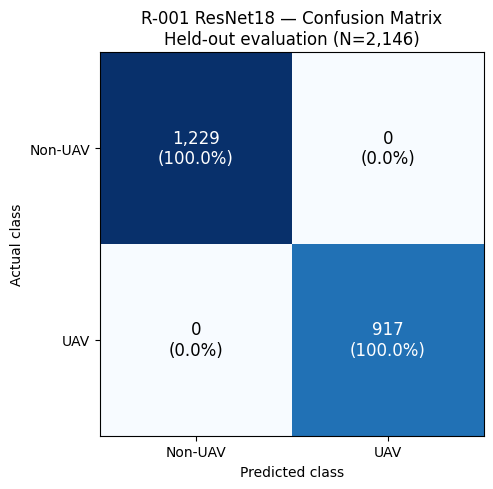

Figure saved: /content/drive/MyDrive/RadarClassifier/Evaluations/R-001-final/figures/r001_confusion_matrix.png


In [19]:

import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

eval_dir = Path(
    "/content/drive/MyDrive/RadarClassifier/Evaluations/R-001-final"
)

with (eval_dir / "results.json").open() as f:
    results = json.load(f)

cm = np.array(results["overall"]["confusion_matrix"])
assert cm.shape == (2, 2)

labels = ["Non-UAV", "UAV"]

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")

ax.set_xticks([0, 1], labels=labels)
ax.set_yticks([0, 1], labels=labels)
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
ax.set_title("R-001 ResNet18 — Confusion Matrix\nHeld-out evaluation (N=2,146)")

for i in range(2):
    for j in range(2):
        count = cm[i, j]
        percentage = count / cm[i].sum()
        ax.text(
            j, i,
            f"{count:,}\n({percentage:.1%})",
            ha="center",
            va="center",
            color="white" if count > cm.max() / 2 else "black",
            fontsize=12
        )

fig.tight_layout()

figures_dir = eval_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

figure_path = figures_dir / "r001_confusion_matrix.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()
print("Figure saved:", figure_path)


## 17 — Evaluation Metrics Summary

Summarize the frozen R-001 model's performance on the
held-out evaluation set, overall and by radar frequency.

All metrics are calculated from the saved evaluation results.

In [20]:

import json
import pandas as pd
from pathlib import Path
from IPython.display import display

eval_dir = Path(
    "/content/drive/MyDrive/RadarClassifier/Evaluations/R-001-final"
)

with (eval_dir / "results.json").open() as f:
    results = json.load(f)

def make_row(name, metrics):
    return {
        "Dataset": name,
        "Samples": metrics["rows"],
        "Non-UAV": metrics["class_counts"]["non_uav"],
        "UAV": metrics["class_counts"]["uav"],
        "Accuracy": metrics["accuracy"],
        "Precision": metrics["uav_precision"],
        "Recall": metrics["uav_recall"],
        "F1-score": metrics["uav_f1"],
        "FPR": metrics["false_positive_rate"],
    }

rows = [make_row("Overall", results["overall"])]

for frequency, metrics in sorted(results["per_frequency"].items()):
    rows.append(make_row(frequency, metrics))

metrics_df = pd.DataFrame(rows)

# Save numerical values for reproducible reporting
output_path = eval_dir / "r001_metrics_summary.csv"
metrics_df.to_csv(output_path, index=False)

# Display percentages for readability
display_df = metrics_df.copy()

for column in ["Accuracy", "Precision", "Recall", "F1-score", "FPR"]:
    display_df[column] = display_df[column].map(
        lambda value: f"{value:.2%}" if pd.notna(value) else "N/A"
    )

display(display_df)
print("Metrics table saved:", output_path)


,Dataset,Samples,Non-UAV,UAV,Accuracy,Precision,Recall,F1-score,FPR
0,Overall,2146,1229,917,100.00%,100.00%,100.00%,100.00%,0.00%
1,207GHz,848,437,411,100.00%,100.00%,100.00%,100.00%,0.00%
2,24GHz,519,311,208,100.00%,100.00%,100.00%,100.00%,0.00%
3,94GHz,779,481,298,100.00%,100.00%,100.00%,100.00%,0.00%


Metrics table saved: /content/drive/MyDrive/RadarClassifier/Evaluations/R-001-final/r001_metrics_summary.csv



## 18 — Comparison with the Reference Implementation

### 18.1 Reference Baseline

Our experiment (R-001) was designed as a reference-aligned reproduction of the MathWorks–St Andrews radar drone classification project.

**Reference:** Zhongliang Guo, *MathWorks Radar Drone Classification Project*.

Source: https://github.com/ZhongliangGuo/MathWorks-Radar-Drone-Project (README, pretrained 20-epoch results tables)

| Property | Reference experiment | Our R-001 |
|---|---|---|
| Task | Binary drone/non-drone classification | Same |
| Architecture | ResNet18 | ResNet18 |
| Pretrained weights | Yes | ImageNet1K V1 |
| Epochs | 20 | 20 |
| Batch size | 64 | 64 |
| Learning rate | 0.00001 | 0.00001 |
| Training GPU | NVIDIA A100 80 GB | NVIDIA Tesla T4 |
| Checkpoint selection | Best model based on repeated evaluation | Predeclared final epoch (20) |
| Held-out evaluation usage | Monitored during training in reference code | Run once after training was frozen |
| Real-data evaluation accuracy | 100% | 100% |

**Result:** R-001 matched the reported binary classification accuracy of the reference implementation on the supplied real-data evaluation dataset.

This is a reference-aligned reproduction rather than an exact replication of every training and checkpoint-selection detail.

### 18.2 Additional Evaluation Metrics

R-001 was evaluated on 2,146 held-out images:

- Accuracy: 100%
- UAV precision: 100%
- UAV recall: 100%
- UAV F1-score: 100%
- False positive rate: 0%
- Incorrect predictions: 0

All three radar frequency subsets (24 GHz, 94 GHz, and 207 GHz) achieved 100% accuracy.

These additional metrics describe R-001's performance; they should not be presented as metrics reported by the reference repository unless separately verified.

### 18.3 Interpretation and Limitations

The reference repository reports 100% real-data binary classification accuracy across all eight pretrained CNN architectures after 20 epochs. This suggests that the published binary evaluation is highly separable.

Our dataset integrity checks confirmed:

- No overlapping training/evaluation filenames.
- No exact duplicate image contents across the splits.
- Perfect association between **source-folder date prefixes** and class: every non-UAV path has `2024-02-06` and every UAV path has `2024-03-01`. These are acquisition-date proxies extracted from filenames, not independently verified recording timestamps.
- Potential recording-session similarity between training and evaluation source folders.

These findings do not prove that the CNN exploited recording artifacts, but they indicate possible confounding and limited independence between the splits. The provided CSV split is not established as session-independent.

Furthermore, the reference repository reports only 97% accuracy on simulated bird data and 88% on simulated drone data for the corresponding pretrained 20-epoch ResNet18 binary experiment. These are different evaluation conditions, not directly comparable test splits.

### 18.4 Conclusion

R-001 successfully reproduced the reference-reported accuracy for radar-based binary UAV classification on the supplied evaluation dataset. However, the perfect result should not be interpreted as proof of reliable classification across independently collected recordings, unseen environments, or alternative radar systems.

Future experiments should evaluate recording-session-independent splits and additional datasets to assess generalization.


## 19 — Final Experiment Verification

Verify that the frozen checkpoint, evaluation results,
predictions, and report figures have been saved correctly.

In [21]:

from pathlib import Path
import json
import csv

root = Path("/content/drive/MyDrive/RadarClassifier")
run_dir = root / "Runs/R-001"
eval_dir = root / "Evaluations/R-001-final"

required_files = {
    "Final checkpoint": run_dir / "final.pt",
    "Frozen configuration": run_dir / "frozen_config.json",
    "Training history": run_dir / "training.jsonl",
    "Evaluation results": eval_dir / "results.json",
    "Predictions": eval_dir / "predictions.csv",
    "Metrics summary": eval_dir / "r001_metrics_summary.csv",
    "Confusion matrix figure": (
        eval_dir / "figures/r001_confusion_matrix.png"
    ),
}

for name, path in required_files.items():
    assert path.is_file(), f"Missing: {path}"
    print(f"PASS — {name}")

with (eval_dir / "results.json").open() as f:
    results = json.load(f)

with (eval_dir / "predictions.csv").open(newline="") as f:
    predictions = list(csv.DictReader(f))

assert results["overall"]["rows"] == 2146
assert len(predictions) == 2146
assert results["frozen_run"]["epochs_completed"] == 20

print("\nAll final artifacts verified.")
print("Training epochs: 20")
print("Evaluation samples:", len(predictions))
print("Accuracy:", f"{results['overall']['accuracy']:.2%}")


PASS — Final checkpoint
PASS — Frozen configuration
PASS — Training history
PASS — Evaluation results
PASS — Predictions
PASS — Metrics summary
PASS — Confusion matrix figure

All final artifacts verified.
Training epochs: 20
Evaluation samples: 2146
Accuracy: 100.00%
